# Load Dataset

In [1]:
import numpy as np
import pandas as pd 

from sklearn.datasets import load_digits

# 손글씨 데이터 
digits = load_digits()

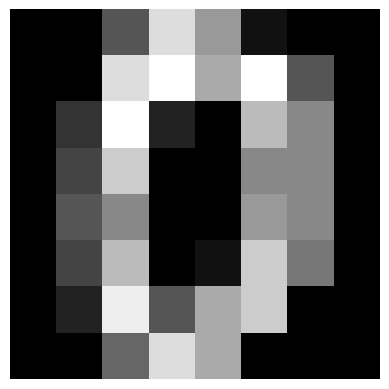

In [2]:
import matplotlib.pyplot as plt

img = digits.data[0]

plt.imshow(img.reshape(8,8), cmap='gray')
plt.axis('off')
plt.show()

## 이진분류 변환  

In [3]:
features = digits.data
targets = (digits.target == 5).astype(int)

features.shape, targets.shape 

((1797, 64), (1797,))

## 학습/평가로 분리 

In [4]:
from sklearn.model_selection import train_test_split

x_tr, x_te, y_tr, y_te = train_test_split(
    features, targets, stratify=targets
)

x_tr.shape, x_te.shape, y_tr.shape, y_te.shape

((1347, 64), (450, 64), (1347,), (450,))

In [5]:
type(x_tr)

numpy.ndarray

# Dataset 클래스 생성 

In [29]:
from torch.utils.data import Dataset 

class MyDataset(Dataset):

    def __init__(self, features, targets, transform=None):
        self.x = features
        self.y = targets
        self.transform = transform

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, index):
        feature = self.transform(self.x[index], dtype=torch.float32) if self.transform is not None else self.x[index]
        target = self.y[index]
        
        return feature.reshape(1,8,8), target

In [30]:
import torch 

train_dataset = MyDataset(x_tr, y_tr, transform=torch.tensor)
test_dataset = MyDataset(x_te, y_te, transform=torch.tensor)

len(train_dataset), len(test_dataset)

(1347, 450)

In [31]:
feature, target = train_dataset[0]

# feature.shape => (color, row, column)
feature.shape, target

(torch.Size([1, 8, 8]), 0)

## DataLoader 생성 

In [32]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    train_dataset, batch_size=100, shuffle=True
)
test_dataloader = DataLoader(
    test_dataset, batch_size=100, shuffle=True
)

len(train_dataloader), len(test_dataloader)

(14, 5)

In [33]:
features, targets = next(iter(train_dataloader))

# (batch, color, row, column)
features.shape, targets.shape

(torch.Size([100, 1, 8, 8]), torch.Size([100]))

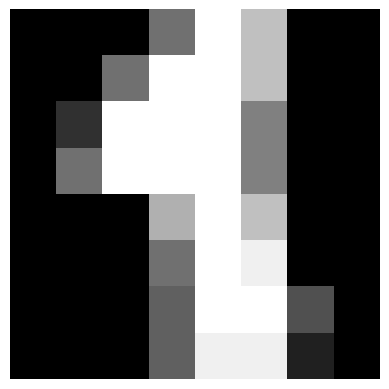

In [34]:
import matplotlib.pyplot as plt

img = features[0].squeeze().numpy()

plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

# 모델 생성 

In [35]:
from torch import nn 

class BinaryModel(nn.Module):
    def __init__(self, feature_size=1*8*8, target_size=1, hidden_size=10):
        super().__init__()
        
        self.flatten = nn.Flatten()
        self.linears = nn.Sequential(
            nn.Linear(in_features=feature_size, out_features=hidden_size),
            nn.ReLU(),
            nn.Linear(in_features=hidden_size, out_features=hidden_size),
            nn.ReLU(),
            nn.Linear(in_features=hidden_size, out_features=target_size)
        )

    def forward(self, features): # (batch, color, row, column)
        # (batch, color*row*column)
        out = self.flatten(features)
        return self.linears(out) # (batch, target_size)

In [36]:
import torchinfo

model = BinaryModel()

torchinfo.summary(model, (10, 1, 8, 8))

Layer (type:depth-idx)                   Output Shape              Param #
BinaryModel                              [10, 1]                   --
├─Flatten: 1-1                           [10, 64]                  --
├─Sequential: 1-2                        [10, 1]                   --
│    └─Linear: 2-1                       [10, 10]                  650
│    └─ReLU: 2-2                         [10, 10]                  --
│    └─Linear: 2-3                       [10, 10]                  110
│    └─ReLU: 2-4                         [10, 10]                  --
│    └─Linear: 2-5                       [10, 1]                   11
Total params: 771
Trainable params: 771
Non-trainable params: 0
Total mult-adds (M): 0.01
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.01

# 모델 학습 

In [53]:
loss_fn = nn.BCEWithLogitsLoss()

model = BinaryModel()
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.01
)

In [54]:
from tqdm.auto import tqdm

In [55]:
lst_tr_loss = []
lst_te_loss = []
lst_epoch = []

for epoch in tqdm(range(500), desc="Training.."):
    ############################################
    # 모델학습 
    ############################################
    model.train()
    tr_loss = 0.0
    for features, targets in tqdm(
        train_dataloader, desc="Train Dataset..", leave=False):
        tr_pred = model(features)
        loss = loss_fn(tr_pred.squeeze(), targets.to(torch.float32))
        tr_loss += loss.detach()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    tr_loss = tr_loss / len(train_dataloader)

    ############################################
    # 모델평가 
    ############################################
    model.eval()
    te_loss = 0.0
    with torch.inference_mode():
        for features, targets in tqdm(
            test_dataloader, desc="Test Dataset..", leave=False):
            te_pred = model(features)
            loss = loss_fn(te_pred.squeeze(), targets.to(torch.float32))
            te_loss += loss.detach()

    te_loss = te_loss / len(test_dataloader)

    ############################################
    # 저장
    ############################################  
    if epoch % 50 == 0:
        lst_epoch.append(epoch)
        # loss.detach() => device를 cpu로 변경 
        lst_tr_loss.append(tr_loss.detach().numpy())
        lst_te_loss.append(te_loss.detach().numpy())
        print(f"Epoch: {epoch} | Train Loss: {tr_loss} | Test Loss: {te_loss}")
        

Training..:   0%|          | 0/500 [00:00<?, ?it/s]

Train Dataset..:   0%|          | 0/14 [00:00<?, ?it/s]

Test Dataset..:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 0.3589079678058624 | Test Loss: 0.27306872606277466


Train Dataset..:   0%|          | 0/14 [00:00<?, ?it/s]

...

Test Dataset..:   0%|          | 0/5 [00:00<?, ?it/s]

Train Dataset..:   0%|          | 0/14 [00:00<?, ?it/s]

Test Dataset..:   0%|          | 0/5 [00:00<?, ?it/s]

Train Dataset..:   0%|          | 0/14 [00:00<?, ?it/s]

Test Dataset..:   0%|          | 0/5 [00:00<?, ?it/s]

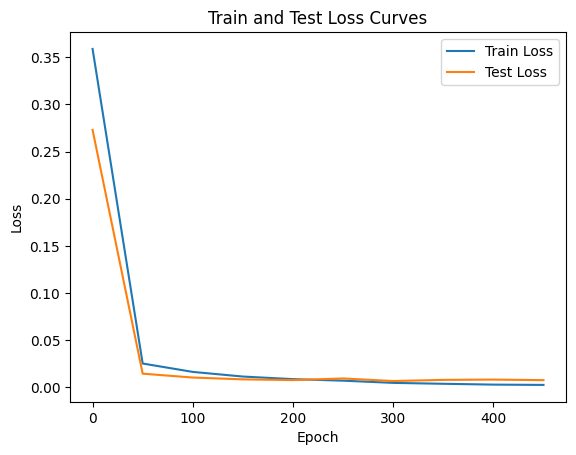

In [56]:
import matplotlib.pyplot as plt 

plt.plot(lst_epoch, lst_tr_loss, label="Train Loss")
plt.plot(lst_epoch, lst_te_loss, label="Test Loss")
plt.title("Train and Test Loss Curves")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.show();

# 모델 평가 

In [57]:
def accuracy_fn(y_true, y_pred):
    # torch.eq(A, B): A와 B가 같은면, True
    # torch.eq(y_true, y_pred).sum() => True의 수
    # torch.eq(y_true, y_pred).sum().item() => Tensor to python 
    correct_cnt = torch.eq(y_true, y_pred).sum().item()
    # 정확도 = (전체 맞은 수 / 전체 수) * 100 
    accuracy = (correct_cnt / len(y_pred)) * 100
    return accuracy 

In [62]:
model.eval()
accuracy = 0.0
lst_te_pred = [] 
lst_te_y = []
with torch.inference_mode():
    for features, targets in tqdm(
        test_dataloader, desc="Test Dataset..", leave=False):
        # te_pred.shape => (batch, target_size=1)
        te_pred = model(features)
        # 확률 ( 0 ~ 1 )
        te_proba = torch.sigmoid(te_pred)
        # 1 또는 0
        te_round = torch.round(te_proba)
        # targets.shape => (batch,)
        accuracy += accuracy_fn(y_true=targets, y_pred=te_round.squeeze())

        lst_te_pred.extend(te_round.squeeze().numpy())
        lst_te_y.extend(targets.numpy())

accuracy /= len(test_dataloader)
print(f"정확도: {accuracy}")

Test Dataset..:   0%|          | 0/5 [00:00<?, ?it/s]

정확도: 99.6


In [66]:
import numpy as np
from sklearn.metrics import confusion_matrix 

conf_mx = confusion_matrix(np.array(lst_te_y), np.array(lst_te_pred), normalize='true')

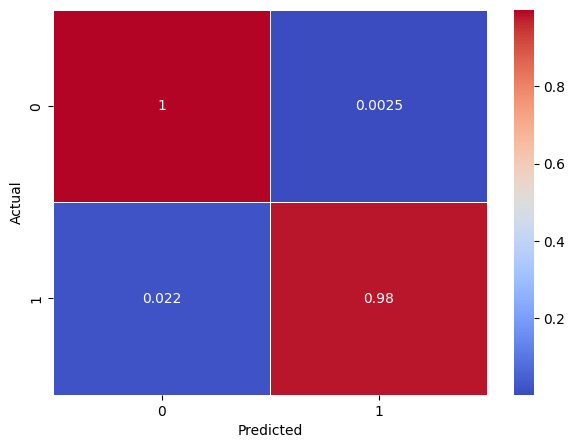

In [67]:
import seaborn as sns

plt.figure(figsize=(7,5))

sns.heatmap(conf_mx, annot=True, cmap="coolwarm", linewidth=0.5)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()